# DATA MINING - Random Forest Regressor

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score
sns.set_style("whitegrid")

## Split Data

In [2]:
df = pd.read_csv("Gaming_Academic_Performance_ML.csv")

X = df.drop(columns=['grades'])
y = df['grades']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

## Modeling & Training

In [3]:
model = RandomForestRegressor(n_estimators=300, random_state=42)
model.fit(X_train, y_train)

,n_estimators,300
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## Evaluasi

In [4]:
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Evaluasi Model Random Forest Regressor:")
print(f"Mean Squared Error (MSE) : {mse:.2f}")
print(f"Root Mean Squared Error (RMSE) : {rmse:.2f}")
print(f"Mean Absolute Error (MAE) : {mae:.2f}")
print(f"R-Squared Score : {r2 * 100:.2f}%")

Evaluasi Model Random Forest Regressor:
Mean Squared Error (MSE) : 37.42
Root Mean Squared Error (RMSE) : 6.12
Mean Absolute Error (MAE) : 4.77
R-Squared Score : 92.48%


## Feature Importance

Feature importance (Random Forest):
study_hours            0.555644
gaming_hours           0.318703
sleep_hours            0.065077
attendance             0.027300
reaction_time_ms       0.006815
social_activity        0.006265
device_usage           0.006201
addiction_score        0.006118
age                    0.003665
gender                 0.001143
stress_level           0.000850
gaming_genre_RPG       0.000750
gaming_genre_Casual    0.000745
gaming_genre_FPS       0.000723
dtype: float64


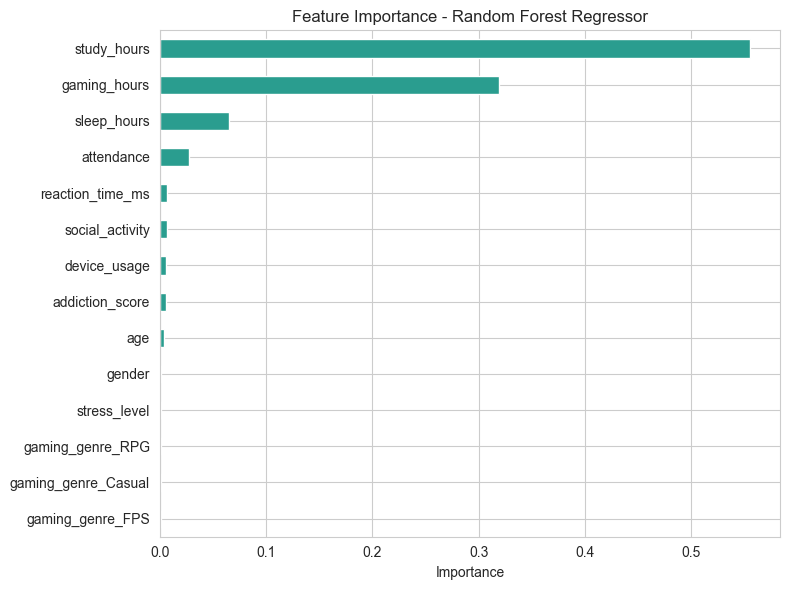

In [5]:
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Feature importance (Random Forest):")
print(importances)

plt.figure(figsize=(8,6))
importances.plot(kind="barh", color="#2a9d8f")
plt.gca().invert_yaxis()
plt.title("Feature Importance - Random Forest Regressor")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("insight_feature_importance.png")
plt.show()

## Test Data Baru

In [6]:
import pandas as pd

data_baru = pd.DataFrame({
    'age': [21],
    'gender': [1],
    'gaming_hours': [3.5],
    'study_hours': [5.0],
    'sleep_hours': [7.5],
    'attendance': [92],
    'social_activity': [4],
    'device_usage': [8],
    'reaction_time_ms': [240],
    'addiction_score': [12],
    'stress_level': [1],
    'gaming_genre_Casual': [0],
    'gaming_genre_FPS': [1],
    'gaming_genre_RPG': [0]
})

prediksi = model.predict(data_baru)

print(f"Prediksi Grade Data Baru: {prediksi[0]:.2f}")

Prediksi Grade Data Baru: 74.80
